# Revisión de las etiquetas de RoCoLe

In [ ]:

import pandas as pd
from pathlib import Path

: 

In [ ]:

rocole_classes_path = Path("../data/raw/RoCoLe/Annotations/RoCoLe-classes.xlsx")
rocole_classes_path

WindowsPath('../data/raw/RoCoLe/Annotations/RoCoLe-classes.xlsx')

In [ ]:

rocole_classes = pd.read_excel(rocole_classes_path)
rocole_classes.head(5)

,File,Binary.Label,Multiclass.Label
0,C1P1H1.jpg,healthy,healthy
1,C1P2E2.jpg,unhealthy,rust_level_2
2,C1P2H1.jpg,healthy,healthy
3,C1P3E1.jpg,healthy,healthy
4,C1P3E2.jpg,unhealthy,rust_level_2


## Qué dice cada columna

En las primeras cinco filas, File es el nombre de la foto, por ejemplo C1P1H1.jpg. Binary.Label dice si está sana o afectada. Multiclass.Label afina eso: en estas filas, sana o roya nivel 2. Roya nivel 2 no es otra enfermedad: dice qué tan avanzada está la misma roya.

# Metodología del análisis

Este cuaderno busca comprender las imágenes, sus etiquetas y sus limitaciones, para después construir características que ayuden a clasificar alteraciones visibles en hojas de café.

Seguiremos CRISP-DM: de la comprensión y la preparación de los datos hasta el modelado y la evaluación.

RoCoLe es el conjunto principal. BRACOL se caracterizará por separado y no se mezclará automáticamente con RoCoLe, porque cambian la especie, las condiciones de captura y las etiquetas.

Lo que sigue es el plan. No es un resultado ya obtenido.

## 1. Comprender las etiquetas y su distribución

Preguntas que queremos responder:

- ¿Cuántas fotografías y columnas tenemos?
- ¿Qué categorías aparecen?
- ¿Cuántas imágenes tiene cada categoría?
- ¿Las clases están desbalanceadas?
- ¿Cómo se relacionan la etiqueta binaria y la multiclase?

En RoCoLe, como definición del conjunto y no como conteo ya hecho:

- `healthy`: hoja sin las afectaciones visibles etiquetadas.
- `red_spider_mite`: presencia de ácaro, una plaga.
- `rust_level_1` a `rust_level_4`: niveles de una misma enfermedad, la roya.

Escala original de roya, según el área afectada:

- Nivel 1: 1–5 %.
- Nivel 2: 6–20 %.
- Nivel 3: 21–50 %.
- Nivel 4: más de 50 %.

Todavía no decidimos si agruparemos los niveles de roya. La tarea binaria y la multiclase son alternativas. Se definirán cuando los datos estén depurados y el objetivo experimental esté fijo.

## 2. Revisar calidad e integridad

La revisión de abajo recorre estos puntos, en pasos pequeños:

- Valores faltantes en identificadores y etiquetas.
- Correspondencia entre etiquetas y archivos.
- Imágenes legibles.
- Dimensiones y formatos.
- Duplicados exactos y etiquetas contradictorias.
- Imágenes muy similares y agrupaciones por planta o captura, cuando existan identificadores fiables.

Hay una auditoría previa que reportó duplicados y conflictos en RoCoLe. Si sus archivos están disponibles, los reutilizaremos y los contrastaremos. No repetiremos ese trabajo ni presentaremos esos resultados históricos como una ejecución nueva. La ruta de esa auditoría no está localizada en el repositorio.

No borraremos los originales ni elegiremos al azar entre etiquetas contradictorias. Cada exclusión quedará registrada con su justificación.

## 3. Definir particiones y muestra de desarrollo

Antes de diseñar características o de ajustar técnicas:

- Resolver o apartar los conflictos, con trazabilidad.
- Mantener en la misma partición las imágenes de una misma planta, o de grupos relacionados, cuando podamos identificarlos.
- Mantener los duplicados relacionados en el mismo grupo.
- Procurar representación de las clases dentro de esas restricciones.
- Reservar una prueba final que no se usará para elegir técnicas.

El identificador de archivo sirve para unir y agrupar. No será una variable predictora.

## 4. Exploración visual guiada

Más adelante armaremos una galería pequeña de desarrollo por categoría.

Queremos observar:

- Color de la hoja y de las alteraciones.
- Tamaño, cantidad, forma y distribución de las manchas.
- Cara fotografiada, haz o envés, cuando sea identificable.
- Sombras, reflejos, desenfoque e iluminación.
- Fondo, otras hojas y objetos.
- Hoja completa, cortada u ocluida.

Referencia visual, bibliográfica, todavía no comprobada en nuestras fotos:

- Roya: manchas amarillentas; en el envés puede verse un aspecto amarillo-anaranjado; las lesiones antiguas pueden oscurecerse.
- Ácaro: posible punteado claro, pérdida de verde y bronceado.
- Sana: ausencia visible de las afectaciones etiquetadas, no un verde perfectamente uniforme.

Habrá que comprobar qué de eso se ve de verdad. No emitiremos diagnósticos nuevos basándonos solo en el color.

## 5. Separar hoja y fondo

Hay dos problemas distintos:

- A. Segmentar la hoja.
- B. Segmentar posibles lesiones dentro de ella.

Primero resolveremos A.

Compararemos una referencia sencilla con alternativas solo si hace falta justificarlas:

- Umbrales de color en HSV o Lab.
- Limpieza morfológica de las máscaras.
- GrabCut o agrupamiento de colores, si el método sencillo falla.

Al revisar las máscaras superpuestas a las fotografías miraremos si incluyen hojas del fondo, si recortan partes amarillas o marrones de la hoja, y si confunden sombras con fondo.

RoCoLe tiene anotaciones del contorno de las hojas. Si están disponibles, podrán servir para evaluar máscaras o para construir una referencia manual. Ese ensayo no es un sistema automático: una fotografía nueva no traerá una máscara manual.

No elegiremos técnicas usando la etiqueta real de la imagen como entrada. No aplicaremos todos los filtros a la vez.

## 6. Extraer características, de menor a mayor complejidad

Cuando llegue ese momento, la tabla tendrá una fila por imagen y columnas numéricas. Las familias de abajo son el plan. Aún no se calculan.

## Familia A. Color

Dentro de la hoja: porcentaje verde, amarillo, naranja y marrón; histogramas de color; estadísticas y variabilidad de los canales HSV o Lab.

## Familia B. Índices RGB

Exceso de verde (ExG), diferencia normalizada verde-rojo (NGRDI) y VARI.

Antes de calcularlos documentaremos la fórmula y la convención elegidas. Evitaremos divisiones por cero.

Estos índices describen color. No los llamaremos mediciones de clorofila, agua o nutrición. Con RGB no se puede calcular directamente NDVI ni NDRE.

## Familia C. Textura

LBP, y de GLCM el contraste, la homogeneidad y la energía.

Habrá que explicar, en palabras llanas, qué mide cada descriptor, y evitar que el fondo o el borde artificial de la máscara dominen la medición.

## Familia D. Posibles lesiones

Solo si su segmentación es fiable:

- Área sospechosa dividida por el área de la hoja.
- Número de regiones.
- Tamaño mediano, máximo y variabilidad de las áreas relativas.
- Circularidad, elongación y solidez.
- Distribución espacial y proximidad al borde.
- Contraste de color entre la región y el tejido circundante.

Que una zona no sea verde no la convierte en lesión. Sin escala física usaremos tamaños relativos, no centímetros. Llamaremos área sospechosa a la estimación automática mientras no haya validación suficiente.

## Familia E. Representaciones aprendidas

Alternativa posterior: vectores de una red preentrenada, comparados con las características manuales. No implementaremos fusiones complejas antes de tener una referencia.

## 7. Exploración de las características extraídas

Cuando cada familia exista, revisaremos distribuciones, faltantes y valores extremos; compararemos categorías; miraremos correlaciones y redundancias; buscaremos las fotografías que expliquen un valor anómalo; y detectaremos si una característica refleja el fondo, la iluminación o la resolución en lugar de la alteración.

Una diferencia visual o una correlación no demuestra utilidad predictiva. Eso se comprobará con validación.

## 8. Comparación experimental

Propuesta, todavía no corrida:

- E0: clasificador de la clase mayoritaria.
- E1: características de color.
- E2: color y textura.
- E3: añadir características de lesiones.
- E4: representación aprendida, si el tiempo y el alcance lo permiten.

Los índices RGB podrán probarse como una incorporación separada a E1, para ver si aportan información.

Para comparar familias de características mantendremos las particiones, el clasificador y el procedimiento de ajuste. Para comparar preprocesamientos mantendremos las características y el clasificador. Después compararemos al menos dos modelos con el mismo protocolo, empezando por los sencillos.

La métrica principal será el F1 macro. La complementaremos con sensibilidad por clase, precisión, exactitud y matriz de confusión.

Escaladores, selección de características y demás transformaciones aprendidas se ajustarán solo con el entrenamiento, dentro de cada partición de validación. La prueba no elegirá variables, umbrales ni hiperparámetros.

## 9. Evaluación final y errores

Cuando el procedimiento ya esté fijado, evaluaremos la prueba reservada, revisaremos los errores por clase, describiremos las condiciones de fallo y registraremos el costo y la complejidad. Ejecutar sin errores de código no es lo mismo que clasificar bien.

## 10. BRACOL por separado

Caracterizaremos los archivos disponibles y las etiquetas reales, sin mezclarlas con RoCoLe.

Distinción prevista:

- Enfermedades: rust, phoma y cercospora.
- Plaga: miner.
- Referencia: sana.

Advertencias de la auditoría previa, todavía no reejecutadas en este cuaderno:

- BRACOL fue recuperado parcialmente.
- Puede haber varias afectaciones por hoja.
- Presencia y afectación predominante son objetivos diferentes.
- Existe un código predominante 5 cuyo tratamiento habrá que justificar.
- El artículo y el código no usan la misma nomenclatura para brown leaf spot y phoma.

Revisaremos la compatibilidad antes de evaluar un modelo de RoCoLe sobre BRACOL. Si BRACOL queda como análisis complementario, no lo usaremos para seleccionar el modelo.

## Fundamento bibliográfico

Estas referencias se registran sin atribuirles resultados que no hayamos comprobado.

Técnica utilizada directamente por un artículo:

- RoCoLe define las categorías y el área afectada de la roya. https://pmc.ncbi.nlm.nih.gov/articles/PMC6727496/
- Boa Sorte et al., 2019, comparan atributos estadísticos de textura y LBP frente a una CNN. https://doi.org/10.1016/j.procs.2019.09.168
- Faisal et al., 2023, fusionan características de MobileNetV3 y Swin Transformer. https://doi.org/10.1109/ACCESS.2023.3286935
- Fenu y Malloci, 2022, estudian condiciones de laboratorio o de campo y la influencia del fondo. https://doi.org/10.3390/agronomy12102359
- Waldamichael et al., 2022, segmentan con HSV y clasifican con MobileNetV2. https://doi.org/10.1002/int.22747

Características que proponemos nosotros, a partir de síntomas, y que esos artículos no tienen por qué haber calculado igual: porcentajes de color dentro de la hoja, índices RGB (ExG, NGRDI, VARI) y descriptores de posibles lesiones. Quedan como propuesta.

Resultado experimental obtenido en este cuaderno: todavía ninguno.

## Cómo cerramos cada bloque

Cuando un bloque se ejecute, el cuaderno guardará el resultado completo. Al final de ese bloque escribiremos qué se vio, cómo lo interpretamos, qué limitación tiene y cuál es el próximo paso. Las decisiones consolidadas se trasladarán a Notion.

## Bloque 1. Distribución de las etiquetas de RoCoLe

A partir de aquí respondemos las preguntas de la sección 1, con la tabla `rocole_classes` ya cargada. El resto del plan sigue pendiente.

## ¿Cuántas fotografías y cuántas columnas trae la tabla?

Queremos saber el tamaño de `rocole_classes` antes de mirar categorías.

In [4]:
# Entrada
# rocole_classes, ya cargada.

# Qué hacemos
rocole_class_shape = rocole_classes.shape

# Salida
rocole_class_shape

(1560, 3)

## ¿Cuántas fotografías hay en cada etiqueta binaria?

Armamos el conteo y el porcentaje de `Binary.Label`. El nombre de la categoría se deja como viene en el archivo.

In [5]:
# Entrada
# rocole_classes

# Qué hacemos
binary_observed = rocole_classes["Binary.Label"].value_counts(dropna=False)
binary_label_order = ["healthy", "unhealthy"]
binary_label_order = [
    label for label in binary_label_order if label in binary_observed.index
]
for label in binary_observed.index:
    if label not in binary_label_order:
        binary_label_order.append(label)

photo_count = binary_observed.loc[binary_label_order].astype(int)
binary_label_counts = pd.DataFrame(
    {
        "photo_count": photo_count,
        "percent": (photo_count / photo_count.sum() * 100).round(1),
    }
)
binary_label_counts.index.name = "Binary.Label"

# Salida
binary_label_counts

,photo_count,percent
Binary.Label,,
healthy,791,50.7
unhealthy,769,49.3


## ¿Cuántas fotografías hay en cada categoría multiclase?

Hacemos lo mismo con `Multiclass.Label`. Los niveles de roya se cuentan por separado.

In [6]:
# Entrada
# rocole_classes

# Qué hacemos
multiclass_observed = rocole_classes["Multiclass.Label"].value_counts(dropna=False)
multiclass_label_order = [
    "healthy",
    "red_spider_mite",
    "rust_level_1",
    "rust_level_2",
    "rust_level_3",
    "rust_level_4",
]
multiclass_label_order = [
    label for label in multiclass_label_order if label in multiclass_observed.index
]
for label in multiclass_observed.index:
    if label not in multiclass_label_order:
        multiclass_label_order.append(label)

photo_count = multiclass_observed.loc[multiclass_label_order].astype(int)
multiclass_label_counts = pd.DataFrame(
    {
        "photo_count": photo_count,
        "percent": (photo_count / photo_count.sum() * 100).round(1),
    }
)
multiclass_label_counts.index.name = "Multiclass.Label"

# Salida
multiclass_label_counts

,photo_count,percent
Multiclass.Label,,
healthy,791,50.7
red_spider_mite,167,10.7
rust_level_1,344,22.1
rust_level_2,166,10.6
rust_level_3,62,4.0
rust_level_4,30,1.9


## Traer la herramienta para dibujar

La celda de imports de arriba no se toca. Aquí dejamos disponible lo necesario para el gráfico.

In [7]:
# Entrada
# No hay variables previas en esta celda.

# Qué hacemos
import matplotlib.pyplot as plt

# Salida
# Queda disponible plt para el gráfico.

## ¿Cómo se ven esas cantidades?

Dibujamos una barra por categoría multiclase, con el conteo escrito encima. En los datos la etiqueta sigue en inglés. El nombre en español es solo del gráfico.

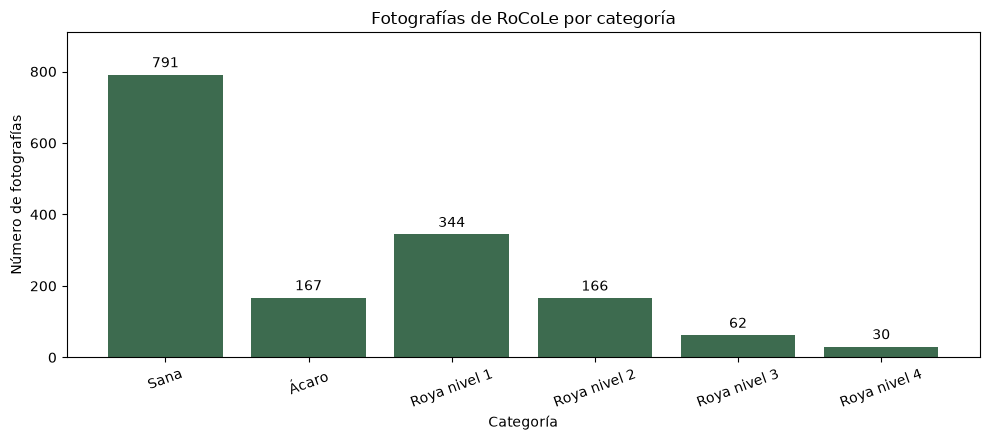

In [8]:
# Entrada
# multiclass_label_counts

# Qué hacemos
multiclass_display_names = {
    "healthy": "Sana",
    "red_spider_mite": "Ácaro",
    "rust_level_1": "Roya nivel 1",
    "rust_level_2": "Roya nivel 2",
    "rust_level_3": "Roya nivel 3",
    "rust_level_4": "Roya nivel 4",
}
bar_labels = [
    multiclass_display_names.get(str(label), str(label))
    for label in multiclass_label_counts.index
]
photo_counts = multiclass_label_counts["photo_count"].astype(int)

figure, axis = plt.subplots(figsize=(10, 4.5))
bars = axis.bar(bar_labels, photo_counts, color="#3d6b4f")
axis.bar_label(bars, padding=3)
axis.set_ylim(0, photo_counts.max() * 1.15)
axis.set_title("Fotografías de RoCoLe por categoría")
axis.set_xlabel("Categoría")
axis.set_ylabel("Número de fotografías")
axis.tick_params(axis="x", labelrotation=20)
figure.tight_layout()
figure_path = Path("../experiments/results/rocole-multiclass-label-counts.png")
figure.savefig(figure_path, dpi=120, bbox_inches="tight")

# Salida
figure

## Qué muestran los conteos

La tabla trae 1.560 fotografías y 3 columnas.

En la etiqueta binaria las dos categorías están casi parejas: sana, 791 fotos (50,7 %), y afectada, 769 (49,3 %).

En la multiclase, sana sigue en 791 (50,7 %). La más escasa es roya nivel 4, con 30 (1,9 %). En medio quedan roya nivel 1 (344; 22,1 %), ácaro (167; 10,7 %), roya nivel 2 (166; 10,6 %) y roya nivel 3 (62; 4,0 %). El desbalance está aquí, no en la binaria: sana es la mitad, roya nivel 4 queda muy por debajo de roya nivel 1, y ácaro y roya nivel 2 tienen casi el mismo tamaño. Lo que no es sana suma 769, el mismo número que afectada.

La binaria separa sana de afectada. La multiclase abre la afectada en ácaro y en cuatro severidades de la misma roya. Todavía no agrupamos esos niveles. Las cinco primeras filas solo mostraban sana y roya nivel 2; en la tabla completa también están el ácaro y los niveles 1, 3 y 4.

Son las filas del Excel, antes de depurar duplicados, etiquetas contradictorias y fotos que no abran. Eso se mira en el bloque siguiente.

## Proporción de cada etiqueta

Queremos ver qué parte del total ocupa cada etiqueta. A la izquierda va la etiqueta binaria y a la derecha la multiclase. Los nombres en español son solo del gráfico.


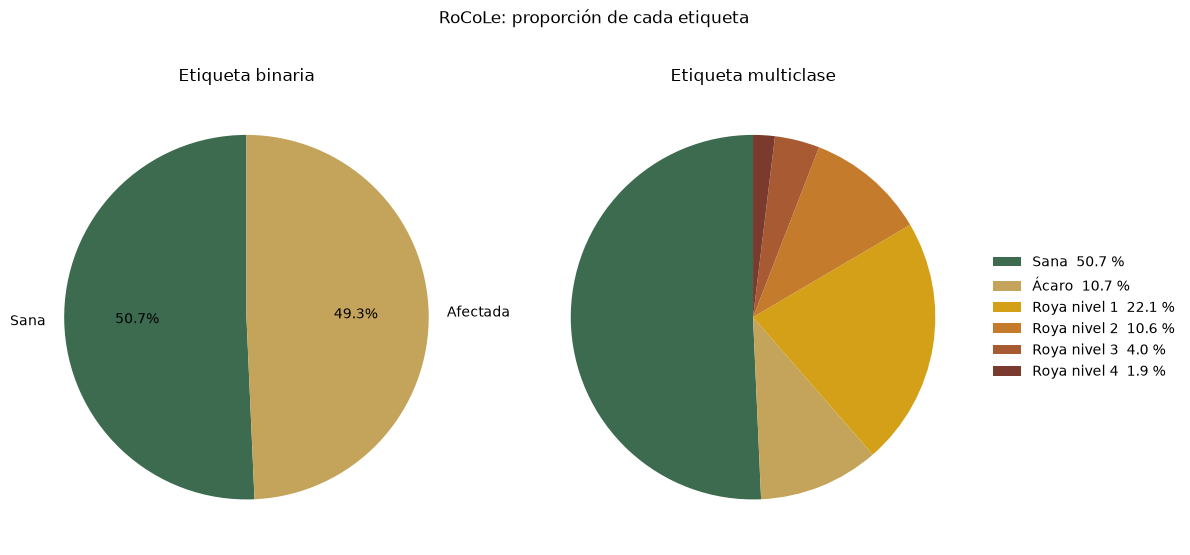

In [9]:
# Entrada
# binary_label_counts, multiclass_label_counts

# Qué hacemos
# Nombres solo para el gráfico. Las tablas de conteo no se traducen.
binary_display_names = {
    "healthy": "Sana",
    "unhealthy": "Afectada",
}
multiclass_display_names = {
    "healthy": "Sana",
    "red_spider_mite": "Ácaro",
    "rust_level_1": "Roya nivel 1",
    "rust_level_2": "Roya nivel 2",
    "rust_level_3": "Roya nivel 3",
    "rust_level_4": "Roya nivel 4",
}
pie_colors = ["#3d6b4f", "#c4a35a", "#d4a017", "#c47b2b", "#a85a32", "#7a3b2e"]

binary_names = [
    binary_display_names.get(str(label), str(label))
    for label in binary_label_counts.index
]
binary_photo_counts = binary_label_counts["photo_count"].astype(int)

multiclass_names = [
    multiclass_display_names.get(str(label), str(label))
    for label in multiclass_label_counts.index
]
multiclass_photo_counts = multiclass_label_counts["photo_count"].astype(int)

figure, axes = plt.subplots(1, 2, figsize=(12, 5.4))
axes[0].pie(
    binary_photo_counts,
    labels=binary_names,
    autopct="%1.1f%%",
    startangle=90,
    colors=pie_colors[: len(binary_names)],
)
axes[0].set_title("Etiqueta binaria")

wedges, _ = axes[1].pie(
    multiclass_photo_counts,
    startangle=90,
    colors=pie_colors[: len(multiclass_names)],
)
axes[1].set_title("Etiqueta multiclase")
legend_labels = [
    f"{name}  {percent:.1f} %"
    for name, percent in zip(multiclass_names, multiclass_label_counts["percent"])
]
axes[1].legend(
    wedges,
    legend_labels,
    loc="center left",
    bbox_to_anchor=(1.0, 0.5),
    frameon=False,
)
figure.suptitle("RoCoLe: proporción de cada etiqueta", y=1.02)
figure.tight_layout()

figure_path = Path("../experiments/results/rocole-label-pies.png")
figure.savefig(figure_path, dpi=120, bbox_inches="tight")

# Salida
figure


## Qué muestran las tortas

La torta binaria queda casi partida en dos: sana, 50,7 %, y afectada, 49,3 %. En la multiclase, sana ocupa la mitad (50,7 %), sigue roya nivel 1 (22,1 %), ácaro y roya nivel 2 se parecen (10,7 % y 10,6 %) y roya nivel 3 y 4 son los trozos más finos (4,0 % y 1,9 %). Esos cuatro niveles son severidad de la misma roya.

Son los mismos porcentajes de las tablas: filas del Excel, antes de depurar duplicados y archivos.


## Bloque 2. Calidad de las fotos y las etiquetas

Seguimos solo con RoCoLe. Queremos ver si cada etiqueta tiene su foto, si hay duplicados, si alguna imagen no abre y si dos copias traen etiquetas que no coinciden.

No borramos archivos ni elegimos una etiqueta cuando dos copias discrepan.


### Dónde están las fotos

Dejamos apuntada la carpeta de fotos de RoCoLe. Los nombres del Excel deberían estar ahí, uno por archivo.


In [ ]:
# Entrada
# Path

# Qué hacemos
rocole_photos_dir = Path("../data/raw/RoCoLe/Photos")

# Salida
rocole_photos_dir


WindowsPath('../data/raw/RoCoLe/Photos')

### Huecos en la tabla

Queremos ver si falta el nombre de la foto o alguna etiqueta.


In [ ]:
# Entrada
# rocole_classes

# Qué hacemos
missing_value_counts = rocole_classes.isna().sum()

# Salida
missing_value_counts


File                0
Binary.Label        0
Multiclass.Label    0
dtype: int64

### Nombres repetidos en la tabla

Queremos ver si el mismo nombre de archivo aparece más de una vez en el Excel.


In [ ]:
# Entrada
# rocole_classes

# Qué hacemos
file_name_counts = rocole_classes["File"].value_counts()
repeated_file_names = file_name_counts[file_name_counts > 1]

# Salida
repeated_file_names


Series([], Name: count, dtype: int64)

### Etiqueta binaria y multiclase en la misma fila

Queremos ver si una fila dice `healthy` en una columna y otra cosa en la otra.


In [ ]:
# Entrada
# rocole_classes

# Qué hacemos
# healthy debe ir con healthy. unhealthy debe ir con otra categoría.
binary_says_healthy = rocole_classes["Binary.Label"] == "healthy"
multiclass_says_healthy = rocole_classes["Multiclass.Label"] == "healthy"
label_mismatches = rocole_classes[binary_says_healthy != multiclass_says_healthy]

# Salida
label_mismatches


,File,Binary.Label,Multiclass.Label


### Etiquetas sin foto

Queremos ver qué nombres del Excel no tienen un jpg en la carpeta.


In [14]:
# Entrada
# rocole_classes, rocole_photos_dir

# Qué hacemos
photo_names = {path.name for path in rocole_photos_dir.glob("*.jpg")}
label_names = set(rocole_classes["File"])
missing_photos = sorted(label_names - photo_names)

# Salida
missing_photos


[]

### Fotos sin etiqueta

Queremos ver qué jpg de la carpeta no aparecen en el Excel.


In [15]:
# Entrada
# photo_names, label_names

# Qué hacemos
extra_photos = sorted(photo_names - label_names)

# Salida
extra_photos


[]

### Herramienta para abrir una foto

Traemos la herramienta que abre una imagen.


In [16]:
# Entrada
# No hay variables de datos en esta celda.

# Qué hacemos
from PIL import Image

# Salida
# Queda disponible Image.


### Fotos que no se pueden leer

Queremos la lista de archivos que no abren.


In [17]:
# Entrada
# rocole_classes, rocole_photos_dir, Image

# Qué hacemos
unreadable_photos = []
for file_name in rocole_classes["File"]:
    photo_path = rocole_photos_dir / file_name
    try:
        with Image.open(photo_path) as photo:
            photo.load()
    except Exception:
        unreadable_photos.append(file_name)

# Salida
unreadable_photos


[]

### La misma foto con otro nombre

Comparamos el contenido de los archivos. Si dos jpg son idénticos, quedan en el mismo grupo aunque el nombre cambie.


In [18]:
# Entrada
# rocole_classes, rocole_photos_dir

# Qué hacemos
import hashlib

photo_hash_groups = {}
for file_name in rocole_classes["File"]:
    photo_bytes = (rocole_photos_dir / file_name).read_bytes()
    photo_hash = hashlib.md5(photo_bytes).hexdigest()
    photo_hash_groups.setdefault(photo_hash, []).append(file_name)

duplicate_photo_groups = [
    names for names in photo_hash_groups.values() if len(names) > 1
]
duplicate_group_count = len(duplicate_photo_groups)
files_per_group = {len(names) for names in duplicate_photo_groups}

# Salida
duplicate_group_count, files_per_group


(67, {2})

### Etiquetas de esas copias

Juntamos cada copia con la etiqueta de su fila. El nombre sirve para unir, no para predecir.


In [19]:
# Entrada
# duplicate_photo_groups, rocole_classes

# Qué hacemos
duplicate_name_rows = []
for group_number, names in enumerate(duplicate_photo_groups, start=1):
    for file_name in names:
        duplicate_name_rows.append({"group": group_number, "File": file_name})

duplicate_name_table = pd.DataFrame(duplicate_name_rows)
duplicate_photo_labels = duplicate_name_table.merge(rocole_classes, on="File")

# Salida
duplicate_photo_labels


,group,File,Binary.Label,Multiclass.Label
0,1,C1P35E1.jpg,healthy,healthy
1,1,C1P38E1.jpg,healthy,healthy
2,2,C1P35H1.jpg,healthy,healthy
3,2,C1P38H1.jpg,healthy,healthy
4,3,C1P39H1.jpg,healthy,healthy
...,...,...,...,...
129,65,C12P38E2.jpg,unhealthy,rust_level_1
130,66,C11P25H2.jpg,unhealthy,rust_level_2
131,66,C12P38H2.jpg,unhealthy,rust_level_1
132,67,C11P28H1.jpg,healthy,healthy


### Cuándo las copias no traen la misma etiqueta

Contamos los pares que coinciden y los que no.


In [20]:
# Entrada
# duplicate_photo_labels

# Qué hacemos
same_labels = 0
different_multiclass_only = 0
different_binary = 0
for _, group in duplicate_photo_labels.groupby("group"):
    same_binary = group["Binary.Label"].nunique() == 1
    same_multiclass = group["Multiclass.Label"].nunique() == 1
    if not same_binary:
        different_binary += 1
    elif not same_multiclass:
        different_multiclass_only += 1
    else:
        same_labels += 1

duplicate_label_summary = pd.Series(
    {
        "same_labels": same_labels,
        "different_multiclass_only": different_multiclass_only,
        "different_binary": different_binary,
    },
    name="group_count",
)

# Salida
duplicate_label_summary


same_labels                  40
different_multiclass_only    26
different_binary              1
Name: group_count, dtype: int64

### Pares con etiquetas distintas

Dejamos escritas las copias que no comparten etiqueta. No descartamos ninguna.


In [21]:
# Entrada
# duplicate_photo_labels

# Qué hacemos
conflict_group_numbers = []
for group_number, group in duplicate_photo_labels.groupby("group"):
    same_binary = group["Binary.Label"].nunique() == 1
    same_multiclass = group["Multiclass.Label"].nunique() == 1
    if not (same_binary and same_multiclass):
        conflict_group_numbers.append(group_number)

duplicate_label_conflicts = duplicate_photo_labels[
    duplicate_photo_labels["group"].isin(conflict_group_numbers)
]
pd.set_option("display.max_rows", 200)

# Salida
duplicate_label_conflicts


,group,File,Binary.Label,Multiclass.Label
8,5,C2P1H1.jpg,unhealthy,rust_level_3
9,5,C3P2H2.jpg,unhealthy,rust_level_4
16,9,C2P38E2.jpg,unhealthy,red_spider_mite
17,9,C3P29E2.jpg,unhealthy,rust_level_1
28,15,C10P23E2.jpg,unhealthy,red_spider_mite
29,15,C12P32E2.jpg,unhealthy,rust_level_1
30,16,C10P23H2.jpg,unhealthy,rust_level_2
31,16,C12P32H2.jpg,unhealthy,rust_level_1
34,18,C10P26E2.jpg,unhealthy,red_spider_mite
35,18,C12P36E2.jpg,unhealthy,rust_level_3


## Qué muestra la revisión de calidad

La tabla está completa: no falta ningún nombre ni etiqueta, ningún nombre se repite, y en cada fila sana va con sana y afectada va con otra categoría. Los 1.560 nombres tienen su jpg, no sobra ninguno y las 1.560 fotos abren. Tabla y carpeta se corresponden.

El problema son 67 pares de fotos idénticas con distinto nombre (134 archivos, de dos en dos). En 40 pares las etiquetas coinciden. En 26, las dos dicen afectada pero no coinciden en la categoría. En 1 tampoco coincide la binaria: C11P23E1.jpg está como afectada y ácaro, y C12P36E1.jpg como sana. En total, 27 pares no dicen lo mismo. No borramos los originales ni elegimos una etiqueta.

Esta revisión solo encuentra archivos idénticos: no mira fotos parecidas ni agrupa por planta, y no había un archivo de la auditoría previa para contrastar estos pares. Cuando se arme la partición, estas copias tienen que quedar en el mismo lado. Esa partición no se hace aquí.
